## Importation des bibliothèques


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_clean = pd.read_csv('df_clean.csv', nrows=500000)

print(df_clean.head())

                 product_name department          aisle  order_id  \
0  Chocolate Sandwich Cookies     snacks  cookies cakes     23202   
1  Chocolate Sandwich Cookies     snacks  cookies cakes     24367   
2  Chocolate Sandwich Cookies     snacks  cookies cakes     24760   
3  Chocolate Sandwich Cookies     snacks  cookies cakes     25365   
4  Chocolate Sandwich Cookies     snacks  cookies cakes     26490   

   add_to_cart_order  reordered   user_id  order_dow  order_hour_of_day  \
0                3.0        0.0  162394.0        3.0               12.0   
1                2.0        1.0  148255.0        6.0               17.0   
2                5.0        1.0  205157.0        5.0               17.0   
3                9.0        1.0  181127.0        3.0               20.0   
4               14.0        1.0   92648.0        5.0               15.0   

   days_since_prior_order  
0                     7.0  
1                     6.0  
2                    25.0  
3                    3

## 🛒 Les bases du panier


## Quels sont les produits les plus vendus ?

/tmp/ipykernel_11080/3212420787.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=best_products.values, y=best_products.index, palette='viridis')


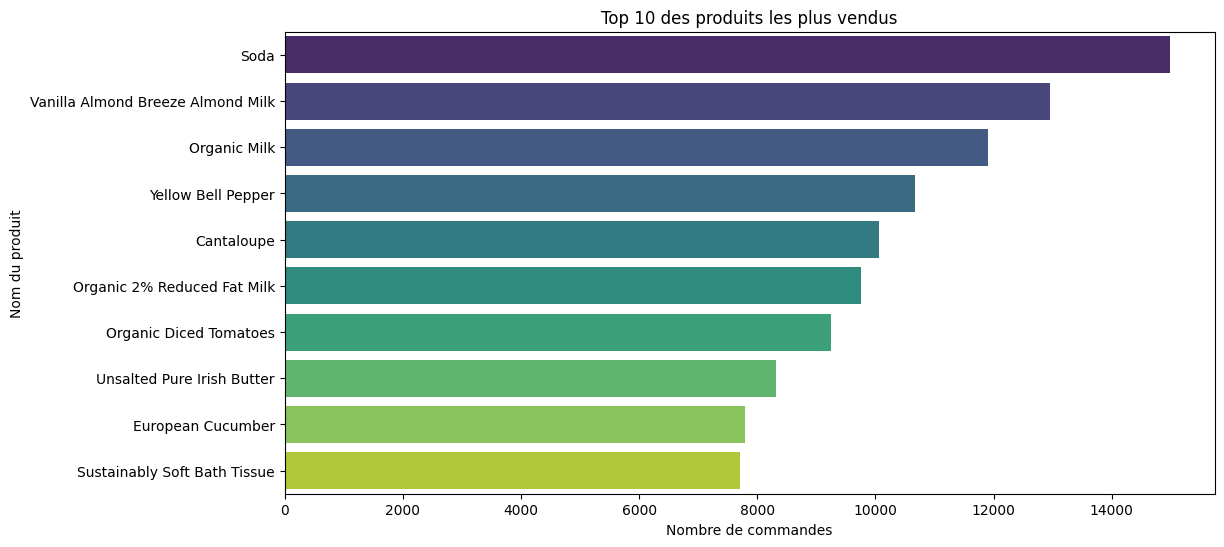

In [14]:
best_products = df_clean['product_name'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=best_products.values, y=best_products.index, palette='viridis')
plt.title('Top 10 des produits les plus vendus')
plt.xlabel('Nombre de commandes')
plt.ylabel('Nom du produit')
plt.show()

## Quel article les clients mettent-ils en premier dans leur panier ?


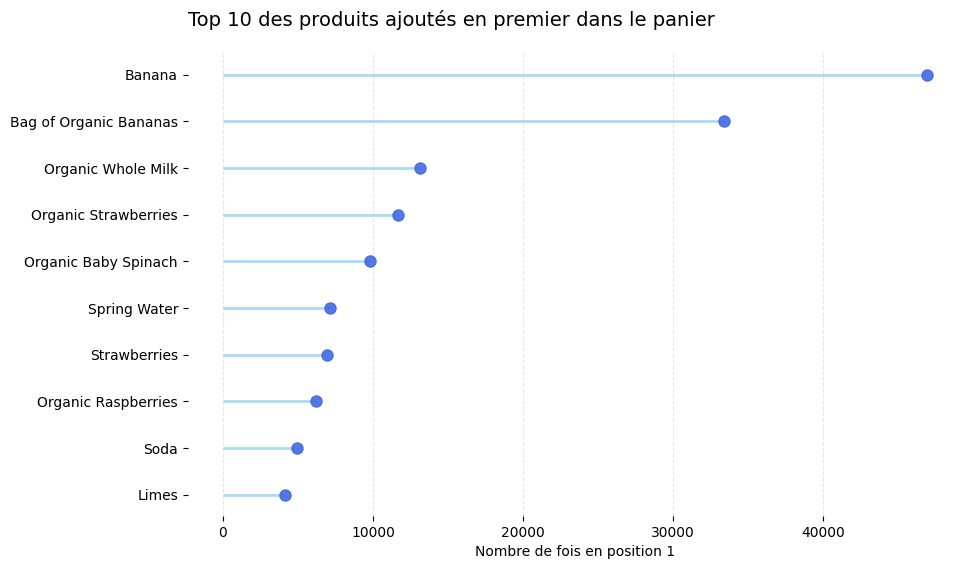

In [15]:
df = pd.read_csv('df_clean.csv')

# Identification des produits ajoutés en premier
first_added = df[df['add_to_cart_order'] == 1]

# Comptage des 10 produits les plus fréquents
top_first_products = first_added['product_name'].value_counts().head(10).reset_index()
top_first_products.columns = ['product_name', 'count']

# Visualisation
plt.figure(figsize=(10, 6))
top_first_products = top_first_products.sort_values(by='count', ascending=True)

plt.hlines(y=top_first_products['product_name'], xmin=0, xmax=top_first_products['count'], 
           color='skyblue', alpha=0.7, linewidth=2)
plt.plot(top_first_products['count'], top_first_products['product_name'], "o", 
         markersize=8, color='royalblue', alpha=0.9)

plt.title('Top 10 des produits ajoutés en premier dans le panier', loc='left', fontsize=14, pad=20)
plt.xlabel('Nombre de fois en position 1')
plt.ylabel('')
sns.despine(left=True, bottom=True) 
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.show()

## Quels sont les rayons qui ont le plus de produits ?


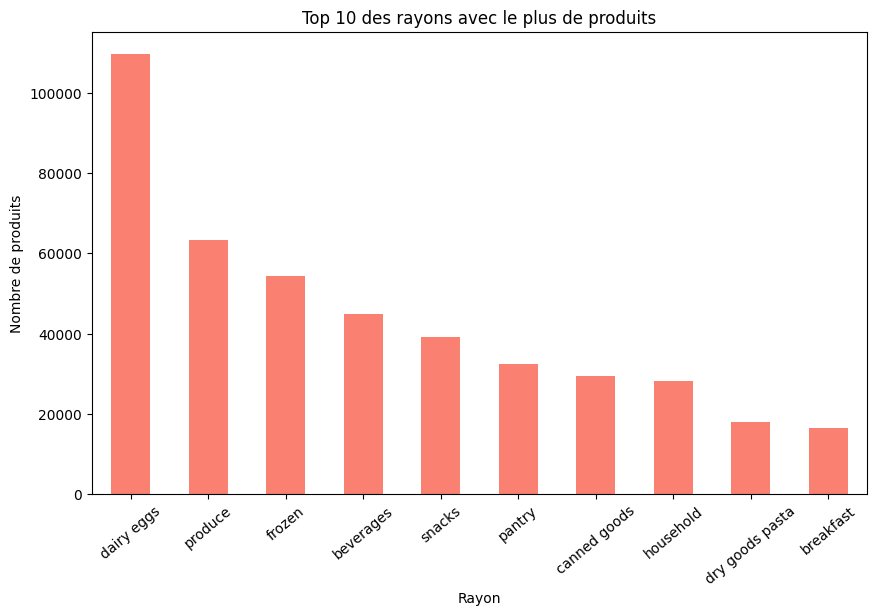

In [16]:
# Compte le nombre de produits par rayon
top_rayons = df_clean['department'].value_counts().head(10)

# Affiche le graphique en barre
plt.figure(figsize=(10, 6))
top_rayons.plot(kind='bar', color='salmon')
plt.title('Top 10 des rayons avec le plus de produits')
plt.xlabel('Rayon')
plt.ylabel('Nombre de produits')
plt.xticks(rotation=40) 
plt.show()

## Quels sont les rayons qui ont le moins de produits ?


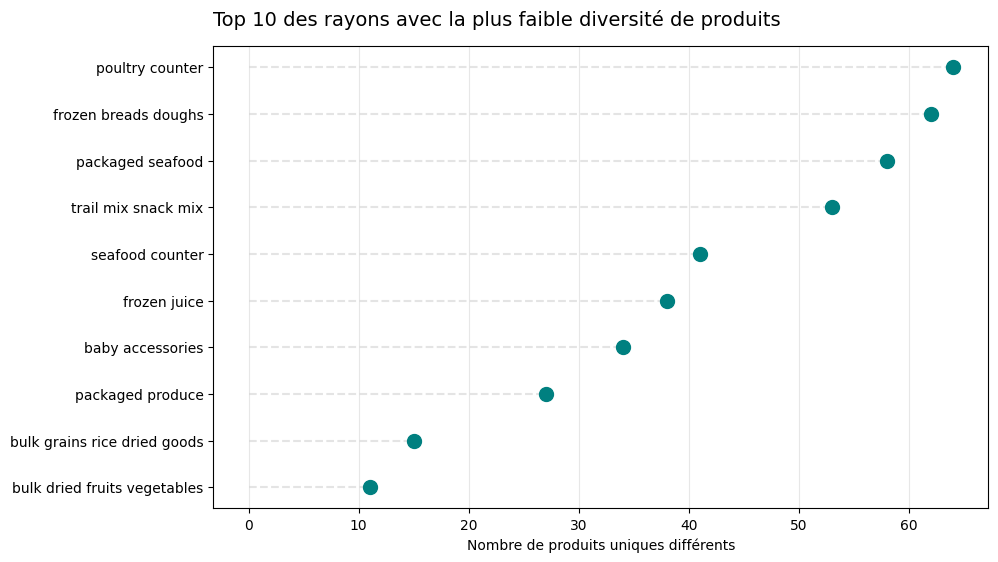

In [17]:
df = pd.read_csv('df_clean.csv')

# Compte les produits uniques par rayon et prend les 10 plus petits
aisle_counts = df.groupby('aisle')['product_name'].nunique().nsmallest(10).reset_index()
aisle_counts.columns = ['Rayon', 'Nombre_de_Produits']

plt.figure(figsize=(10, 6))

# Trace les points
plt.scatter(aisle_counts['Nombre_de_Produits'], aisle_counts['Rayon'], 
            color='teal', s=100, zorder=3)

plt.hlines(y=aisle_counts['Rayon'], xmin=0, xmax=aisle_counts['Nombre_de_Produits'], 
           color='lightgray', linestyle='--', alpha=0.6, zorder=2)

plt.title('Top 10 des rayons avec la plus faible diversité de produits', loc='left', fontsize=14, pad=15)
plt.xlabel('Nombre de produits uniques différents')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)

plt.show()

## Quelle est la proportion de légumes bio dans les commandes ?


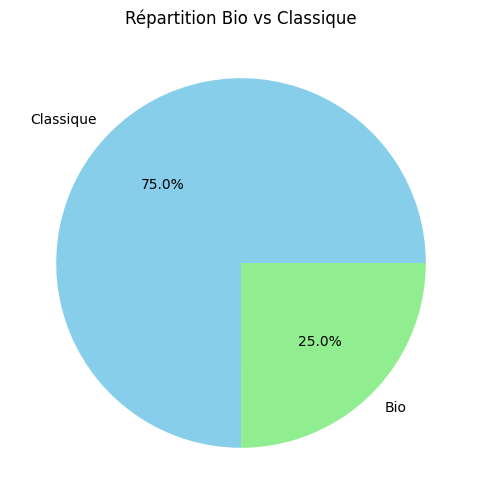

In [18]:
# Prépare les données
vegetables = df_clean[df_clean['department'] == 'produce'].copy()
# Créer une colonne avec des noms au lieu de True/False
vegetables['Type'] = vegetables['product_name'].str.contains('organic', case=False).map({True: 'Bio', False: 'Classique'})

#Affiche le graphique
plt.figure(figsize=(6, 6))
vegetables['Type'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['skyblue', 'lightgreen'])
plt.title('Répartition Bio vs Classique')
plt.ylabel('') 
plt.show()

## ⏰ Habitudes de consommation


## Quand les clients commandent-ils (jour/heure) ?


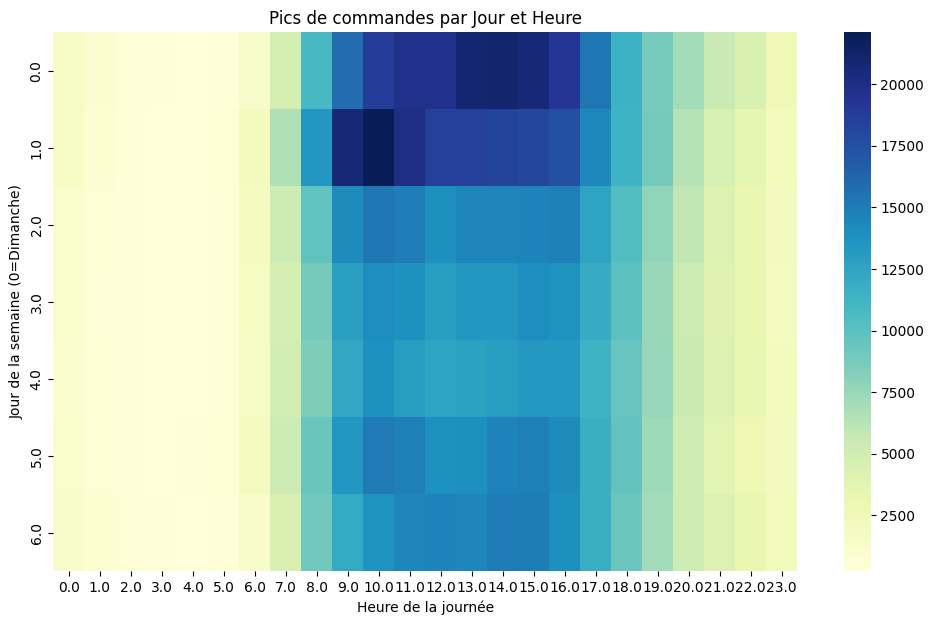

In [19]:
df = pd.read_csv('df_clean.csv')

# Compte les commandes uniques par jour et par heure
heatmap_data = df.pivot_table(index='order_dow', 
                              columns='order_hour_of_day', 
                              values='order_id', 
                              aggfunc='nunique')

# Création Heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(heatmap_data, cmap="YlGnBu")

plt.title('Pics de commandes par Jour et Heure')
plt.xlabel('Heure de la journée')
plt.ylabel('Jour de la semaine (0=Dimanche)')
plt.show()

## Comment les clients passent-ils commande ?


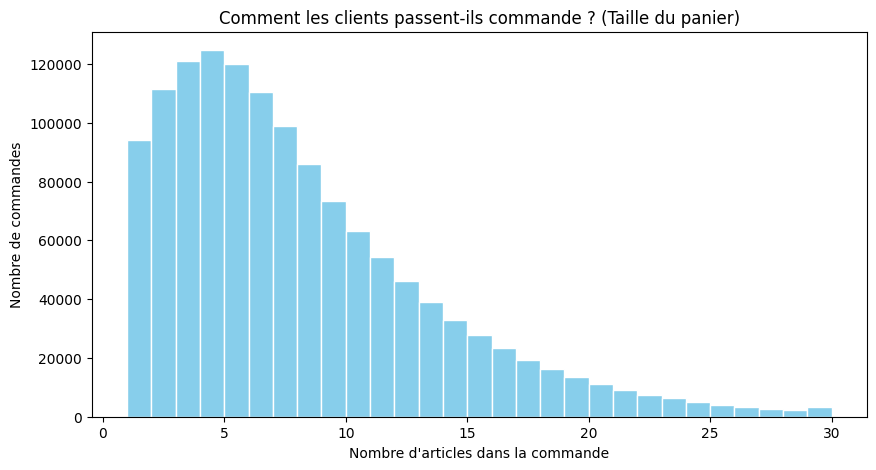

In [20]:
# Compte le nombre d'articles par commande
taille_panier = df.groupby('order_id')['product_name'].count()

# Limité à 30 articles pour la lisibilité
plt.figure(figsize=(10, 5))
taille_panier.hist(bins=range(1, 31), color='skyblue', edgecolor='white', grid=False)

plt.title('Comment les clients passent-ils commande ? (Taille du panier)')
plt.xlabel('Nombre d\'articles dans la commande')
plt.ylabel('Nombre de commandes')
plt.show()

## Les clients achètent-ils plus de nourriture pour chats le matin que pour chiens le soir ?


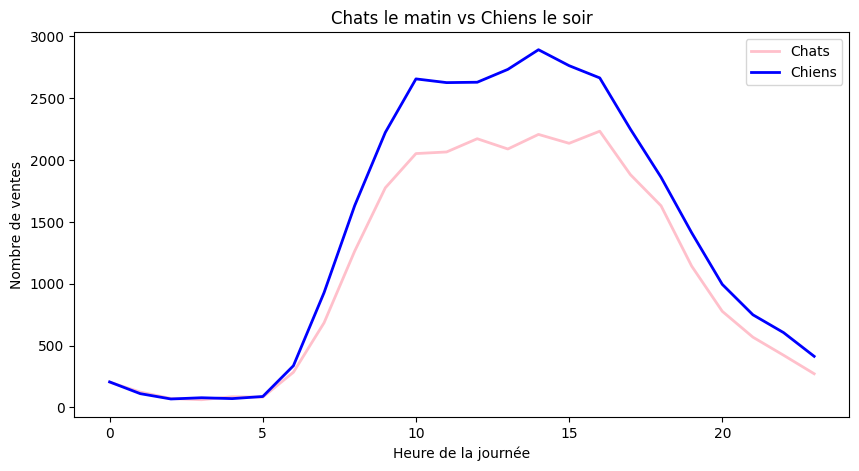

In [21]:
# Sépare les chats et les chiens
chats = df[df['product_name'].str.contains('Cat', case=False, na=False)]
chiens = df[df['product_name'].str.contains('Dog', case=False, na=False)]

# Compte les ventes par heure
heures_chats = chats.groupby('order_hour_of_day')['order_id'].count()
heures_chiens = chiens.groupby('order_hour_of_day')['order_id'].count()

plt.figure(figsize=(10, 5))
heures_chats.plot(label='Chats', color='pink', lw=2)
heures_chiens.plot(label='Chiens', color='blue', lw=2)

plt.title('Chats le matin vs Chiens le soir')
plt.xlabel('Heure de la journée')
plt.ylabel('Nombre de ventes')
plt.legend()
plt.show()

## Quels produits faut-il mettre en avant le samedi ?


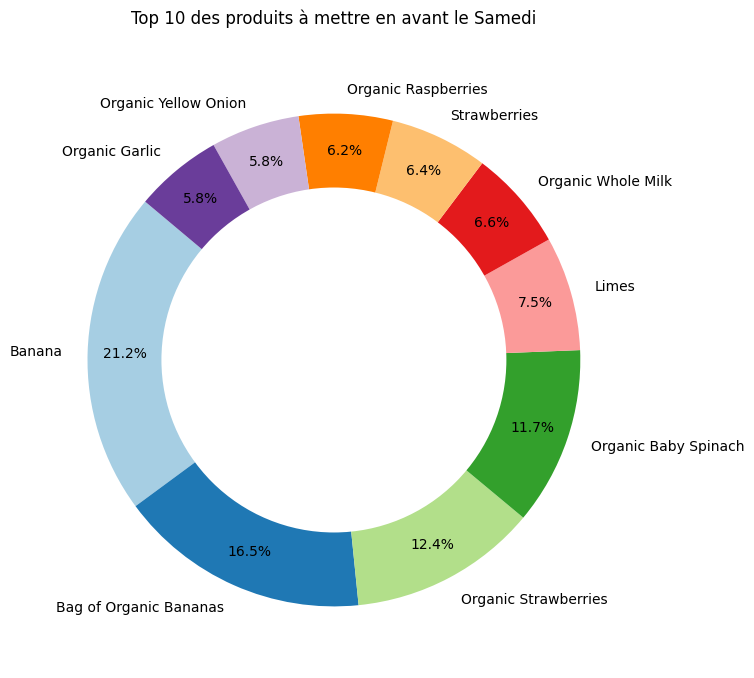

In [22]:
# Filtrer pour le samedi (order_dow == 6) et prendre le top 10
samedi_top = df[df['order_dow'] == 6]['product_name'].value_counts().head(10)

plt.figure(figsize=(8, 8))
plt.pie(samedi_top, labels=samedi_top.index, autopct='%1.1f%%', 
        startangle=140, pctdistance=0.85, colors=plt.cm.Paired.colors)

# Créer le cercle au centre pour faire l'effet "Donut"
centre_cercle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_cercle)

plt.title('Top 10 des produits à mettre en avant le Samedi', pad=20)
plt.show()

## 💡 Recommandations et liens


## Qu'est-ce que les gens achètent souvent avec du chocolat ?

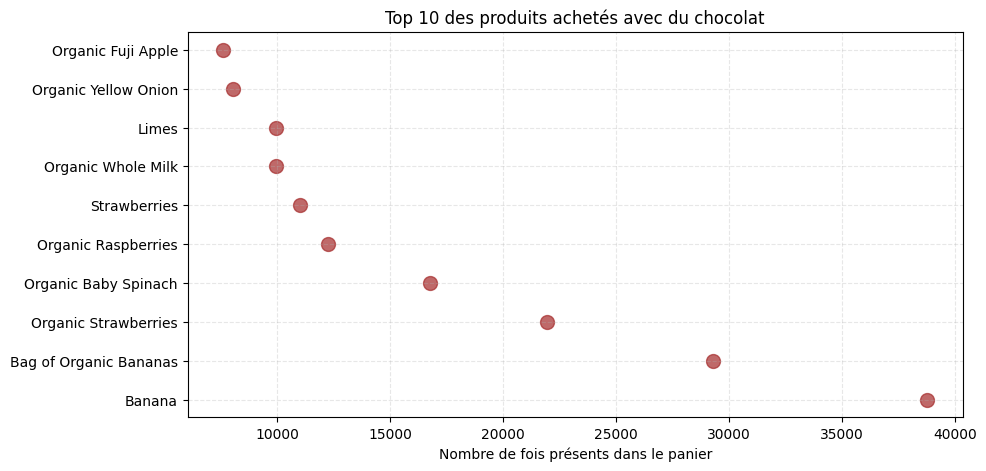

In [23]:
import matplotlib.pyplot as plt

# Trouver les commandes qui contiennent du chocolat
orders_with_choco = df[df['product_name'].str.contains('Chocolate', case=False, na=False)]['order_id']

# Voir ce qu'il y a d'autre dans ces commandes (en excluant le chocolat lui-même)
top_associations = df[df['order_id'].isin(orders_with_choco) & 
                      ~df['product_name'].str.contains('Chocolate', case=False, na=False)]['product_name'].value_counts().head(10)

plt.figure(figsize=(10, 5))
plt.scatter(top_associations.values, top_associations.index, s=100, color='brown', alpha=0.7)

plt.title('Top 10 des produits achetés avec du chocolat')
plt.xlabel('Nombre de fois présents dans le panier')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

## Quels produits ont la plus forte probabilité d'être rachetés ?

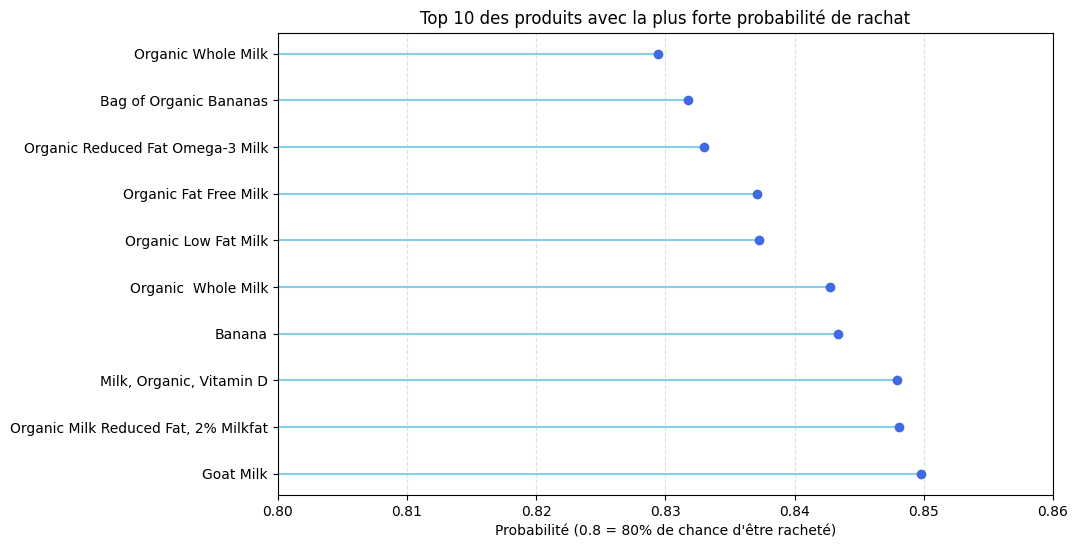

In [26]:
import matplotlib.pyplot as plt

# Calcul de la moyenne de 'reordered' par produit
# Filtre les produits vendus au moins 2000 fois pour éviter les stats faussées
stats = df.groupby('product_name')['reordered'].agg(['mean', 'count'])
top_reorder = stats[stats['count'] > 2000].nlargest(10, 'mean').reset_index()

plt.figure(figsize=(10, 6))
plt.hlines(y=top_reorder['product_name'], xmin=0, xmax=top_reorder['mean'], color='skyblue')
plt.plot(top_reorder['mean'], top_reorder['product_name'], "o", color='royalblue')

plt.title('Top 10 des produits avec la plus forte probabilité de rachat')
plt.xlabel('Probabilité (0.8 = 80% de chance d\'être racheté)')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.xlim(0.80, 0.86)
plt.show()

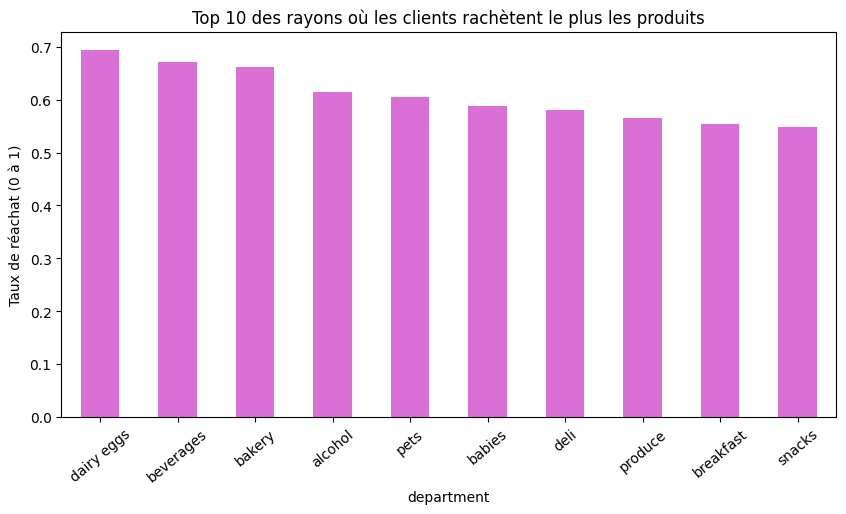

In [25]:
# Calcule le taux de réachat par rayon
reorder_r = df_clean.groupby('department')['reordered'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
reorder_r.plot(kind='bar', color='orchid')
plt.title('Top 10 des rayons où les clients rachètent le plus les produits')
plt.ylabel('Taux de réachat (0 à 1)')
plt.xticks(rotation=40) 
plt.show()